## Random Forest Classifier

### 1. Import libraries

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate

### 2. Load .csv files

In [3]:
# Path to processed data
root_path = '../data/processed_data/'

# csv file names
features_kfold_csv = 'x_train_kfold.csv'
targets_kfold_csv = 'y_train_kfold.csv'
features_train_holdout_csv = 'x_train_holdout.csv'
targets_train_holdout_csv = 'y_train_holdout.csv'
features_val_holdout_csv = 'x_val_holdout.csv'
targets_val_holdout_csv = 'y_val_holdout.csv'

# Dataframes for K-fold cross validation
features_kfold = pd.read_csv(root_path + features_kfold_csv)
targets_kfold = pd.read_csv(root_path + targets_kfold_csv)

# Dataframes for holdout validation
features_train_holdout = pd.read_csv(root_path + features_train_holdout_csv)
targets_train_holdout = pd.read_csv(root_path + targets_train_holdout_csv)
features_val_holdout = pd.read_csv(root_path + features_val_holdout_csv)
targets_val_holdout = pd.read_csv(root_path + targets_val_holdout_csv)

print(features_kfold.shape)
print(targets_kfold.shape)
print(features_train_holdout.shape)
print(targets_train_holdout.shape)
print(features_val_holdout.shape)
print(targets_val_holdout.shape)

(44439, 73)
(44439, 1)
(39995, 73)
(39995, 1)
(4444, 73)
(4444, 1)


### 3. Data processing

In [4]:
# Squeeze target data
targets_kfold = targets_kfold.squeeze()
targets_train_holdout = targets_train_holdout.squeeze()
targets_val_holdout = targets_val_holdout.squeeze()

### 4. Evaluation Metrics
Helper functions for evaluating models. Metrics include: Accuracy, Precision, Recall, F1, Confusion Matrices

In [5]:
def evaluate(model, features_data, targets_data):
    prediction = model.predict(features_data)
    return {
        "Accuracy": accuracy_score(targets_data, prediction),
        "Precision": precision_score(targets_data, prediction, average="weighted", zero_division=0),
        "Recall": recall_score(targets_data, prediction, average="weighted", zero_division=0),
        "F1": f1_score(targets_data, prediction, average="weighted", zero_division=0),
        "F1_macro": f1_score(targets_data, prediction, average="macro", zero_division=0),
    }

def evaluate_class_report(model, features_data, targets_data):
    prediction = model.predict(features_data)

    return classification_report(targets_data, prediction, output_dict=True, zero_division=0)



def plot_confusion_matrix(model, features_data, targets_data, title="Confusion Matrix"):
    prediction = model.predict(features_data)
    cm = confusion_matrix(targets_data, prediction)

    fig, ax = plt.subplots(figsize=(10,10))
    display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)

    display.plot(ax=ax, cmap=plt.cm.Blues, xticks_rotation='vertical', values_format="d")
    plt.title(title)
    plt.tight_layout()
    plt.show()

    return cm

def plot_confusion_matrix_norm(model, features_data, targets_data, title="Confusion Matrix"):
    prediction = model.predict(features_data)
    cm_normalized = confusion_matrix(targets_data, prediction, normalize='true')

    fig, ax = plt.subplots(figsize=(10,10))
    display = ConfusionMatrixDisplay(confusion_matrix=cm_normalized, display_labels=model.classes_)

    display.plot(ax=ax, cmap=plt.cm.Blues, xticks_rotation='vertical', values_format=".2f")
    plt.title(title)
    plt.tight_layout()
    plt.show()

    return cm_normalized

# K-fold Cross Validation Evaluation
def evaluate_folds(results, scoring):
    k = len(results["test_accuracy"])

    folds = pd.DataFrame({
        name: results[f"{split}_{metric}"]
        for metric in scoring
        for split, name in [
            ("train", f"Train {metric}"),
            ("test", f"Test {metric}")
        ]
    })
    folds.index = range(1, k + 1)
    folds.index.name = "Fold"

    return folds.round(4).T

def summarize_folds(results, scoring):
    summary = pd.DataFrame({
        metric: {
            "Train Mean": results[f"train_{metric}"].mean(),
            "Train Std": results[f"train_{metric}"].std(ddof=0),
            "Test Mean": results[f"test_{metric}"].mean(),
            "Test Std": results[f"test_{metric}"].std(ddof=0),
            "Mean Gap": (results[f"train_{metric}"].mean() - results[f"test_{metric}"].mean())
        }
        for metric in scoring
    }).T
    return summary.round(4)

### 5. Model Pipelines

In [27]:
rf_model = Pipeline(steps=[
        ('clf', RandomForestClassifier())
    ])

rf_model_best = Pipeline(steps=[
        ('clf', RandomForestClassifier(
            n_estimators=100,
            max_depth=32,
            min_samples_leaf=5,
            min_samples_split=20,
            class_weight='balanced'
        ))
    ])

### 6. K-fold Cross Validation

In [7]:
k = 5
kfold = StratifiedKFold(n_splits=k, shuffle=True, random_state=42)

scoring = {
    "accuracy": "accuracy",
    "precision_macro": "precision_macro",
    "precision_weighted": "precision_weighted",
    "recall_macro": "recall_macro",
    "recall_weighted": "recall_weighted",
    "f1_macro": "f1_macro",
    "f1_weighted": "f1_weighted"
}

def run_cv(model):
    return cross_validate(
        model,
        features_kfold,
        targets_kfold,
        cv=kfold,
        scoring=scoring,
        return_train_score=True
    )

In [8]:
rf_results = run_cv(rf_model)
rf_folds = evaluate_folds(rf_results, scoring)
rf_summary = summarize_folds(rf_results, scoring)

display(rf_folds)
display(rf_summary)

Fold,1,2,3,4,5
Train accuracy,1.0000,1.0000,1.0000,1.0000,1.0000
Test accuracy,0.8759,0.8722,0.8822,0.8729,0.8692
Train precision_macro,1.0000,1.0000,1.0000,1.0000,1.0000
Test precision_macro,0.8485,0.8372,0.8516,0.8426,0.8360
Train precision_weighted,1.0000,1.0000,1.0000,1.0000,1.0000
Test precision_weighted,0.8755,0.8723,0.8819,0.8709,0.8684
Train recall_macro,1.0000,1.0000,1.0000,1.0000,1.0000
Test recall_macro,0.8365,0.8267,0.8442,0.8345,0.8248
Train recall_weighted,1.0000,1.0000,1.0000,1.0000,1.0000
Test recall_weighted,0.8759,0.8722,0.8822,0.8729,0.8692


,Train Mean,Train Std,Test Mean,Test Std,Mean Gap
accuracy,1.0,0.0,0.8745,0.0044,0.1255
precision_macro,1.0,0.0,0.8432,0.0061,0.1568
precision_weighted,1.0,0.0,0.8738,0.0047,0.1262
recall_macro,1.0,0.0,0.8333,0.0070,0.1667
recall_weighted,1.0,0.0,0.8745,0.0044,0.1255
f1_macro,1.0,0.0,0.8365,0.0067,0.1635
f1_weighted,1.0,0.0,0.8722,0.0047,0.1277


##### Fine Tuning

In [9]:
Min_samples_leaf_values = [1, 2, 3, 4, 5, 6, 7, 8, 10, 20]
summary_results = {}

for value in Min_samples_leaf_values:
    model = Pipeline(steps=[
        ('clf', RandomForestClassifier(
            min_samples_leaf=value
        ))
    ])
    results = run_cv(model)
    summary_results[value] = summarize_folds(results, scoring)

df_compare = pd.concat(summary_results, names=['Min Samples Leaf', 'Metric'])
display(df_compare)

Train Mean  Train Std  Test Mean  \
Min Samples Leaf Metric                                                 
1                accuracy                1.0000     0.0000     0.8756   
                 precision_macro         1.0000     0.0000     0.8443   
                 precision_weighted      1.0000     0.0000     0.8751   
                 recall_macro            1.0000     0.0000     0.8345   
                 recall_weighted         1.0000     0.0000     0.8756   
...                                         ...        ...        ...   
20               precision_weighted      0.8617     0.0016     0.8369   
                 recall_macro            0.8021     0.0025     0.7682   
                 recall_weighted         0.8540     0.0016     0.8329   
                 f1_macro                0.8117     0.0023     0.7750   
                 f1_weighted             0.8480     0.0017     0.8245   

                                     Test Std  Mean Gap  
Min Samples Leaf Metric                                  
1                accuracy              0.0058    0.1244  
                 precision_macro       0.0083    0.1557  
                 precision_weighted    0.0060    0.1249  
                 recall_macro          0.0096    0.1655  
                 recall_weighted       0.0058    0.1244  
...                                       ...       ...  
20               precision_weighted    0.0049    0.0248  
                 recall_macro          0.0068    0.0339  
                 recall_weighted       0.0047    0.0210  
                 f1_macro              0.0068    0.0367  
                 f1_weighted           0.0051    0.0234  

[70 rows x 5 columns]

In [10]:
df_compare

Train Mean  Train Std  Test Mean  \
Min Samples Leaf Metric                                                 
1                accuracy                1.0000     0.0000     0.8756   
                 precision_macro         1.0000     0.0000     0.8443   
                 precision_weighted      1.0000     0.0000     0.8751   
                 recall_macro            1.0000     0.0000     0.8345   
                 recall_weighted         1.0000     0.0000     0.8756   
...                                         ...        ...        ...   
20               precision_weighted      0.8617     0.0016     0.8369   
                 recall_macro            0.8021     0.0025     0.7682   
                 recall_weighted         0.8540     0.0016     0.8329   
                 f1_macro                0.8117     0.0023     0.7750   
                 f1_weighted             0.8480     0.0017     0.8245   

                                     Test Std  Mean Gap  
Min Samples Leaf Metric                                  
1                accuracy              0.0058    0.1244  
                 precision_macro       0.0083    0.1557  
                 precision_weighted    0.0060    0.1249  
                 recall_macro          0.0096    0.1655  
                 recall_weighted       0.0058    0.1244  
...                                       ...       ...  
20               precision_weighted    0.0049    0.0248  
                 recall_macro          0.0068    0.0339  
                 recall_weighted       0.0047    0.0210  
                 f1_macro              0.0068    0.0367  
                 f1_weighted           0.0051    0.0234  

[70 rows x 5 columns]

In [13]:
n_estimators_values = [100, 200, 300, 400, 500]
summary_results = {}

for value in n_estimators_values:
    model = Pipeline(steps=[
        ('clf', RandomForestClassifier(
            n_estimators=value,
            min_samples_leaf=6
        ))
    ])
    results = run_cv(model)
    summary_results[value] = summarize_folds(results, scoring)

df_compare = pd.concat(summary_results, names=['Min Samples Leaf', 'Metric'])
display(df_compare)

Train Mean  Train Std  Test Mean  \
Min Samples Leaf Metric                                                 
100              accuracy                0.9147     0.0008     0.8560   
                 precision_macro         0.9143     0.0008     0.8281   
                 precision_weighted      0.9202     0.0006     0.8592   
                 recall_macro            0.8960     0.0011     0.8051   
                 recall_weighted         0.9147     0.0008     0.8560   
                 f1_macro                0.9019     0.0010     0.8113   
                 f1_weighted             0.9134     0.0009     0.8517   
200              accuracy                0.9157     0.0005     0.8564   
                 precision_macro         0.9157     0.0004     0.8285   
                 precision_weighted      0.9212     0.0005     0.8597   
                 recall_macro            0.8975     0.0006     0.8053   
                 recall_weighted         0.9157     0.0005     0.8564   
                 f1_macro                0.9033     0.0006     0.8114   
                 f1_weighted             0.9144     0.0006     0.8521   
300              accuracy                0.9162     0.0012     0.8572   
                 precision_macro         0.9165     0.0009     0.8296   
                 precision_weighted      0.9217     0.0008     0.8604   
                 recall_macro            0.8986     0.0013     0.8065   
                 recall_weighted         0.9162     0.0012     0.8572   
                 f1_macro                0.9043     0.0012     0.8127   
                 f1_weighted             0.9150     0.0012     0.8529   
400              accuracy                0.9154     0.0013     0.8573   
                 precision_macro         0.9156     0.0011     0.8296   
                 precision_weighted      0.9211     0.0009     0.8608   
                 recall_macro            0.8977     0.0013     0.8065   
                 recall_weighted         0.9154     0.0013     0.8573   
                 f1_macro                0.9034     0.0014     0.8127   
                 f1_weighted             0.9142     0.0013     0.8530   
500              accuracy                0.9158     0.0003     0.8574   
                 precision_macro         0.9163     0.0003     0.8303   
                 precision_weighted      0.9214     0.0002     0.8608   
                 recall_macro            0.8981     0.0007     0.8066   
                 recall_weighted         0.9158     0.0003     0.8574   
                 f1_macro                0.9039     0.0005     0.8130   
                 f1_weighted             0.9146     0.0003     0.8531   

                                     Test Std  Mean Gap  
Min Samples Leaf Metric                                  
100              accuracy              0.0053    0.0587  
                 precision_macro       0.0072    0.0862  
                 precision_weighted    0.0050    0.0610  
                 recall_macro          0.0083    0.0909  
                 recall_weighted       0.0053    0.0587  
                 f1_macro              0.0079    0.0906  
                 f1_weighted           0.0056    0.0617  
200              accuracy              0.0047    0.0593  
                 precision_macro       0.0064    0.0872  
                 precision_weighted    0.0044    0.0615  
                 recall_macro          0.0076    0.0922  
                 recall_weighted       0.0047    0.0593  
                 f1_macro              0.0071    0.0919  
                 f1_weighted           0.0048    0.0624  
300              accuracy              0.0054    0.0590  
                 precision_macro       0.0059    0.0869  
                 precision_weighted    0.0049    0.0613  
                 recall_macro          0.0078    0.0921  
                 recall_weighted       0.0054    0.0590  
                 f1_macro              0.0071    0.0916  
                 f1_weighted           0.0056    0.0621  
4

In [14]:
# Initially run with n_estimators_values by mistake. After changing the code, the old results were still kept in the notebook, but running this cell again will overwrite those results. Regardless, correct use of min_leaf_split parameters is in the cell below.
min_leaf_split = [2, 5, 10, 20, 40, 80]
summary_results = {}

for value in n_estimators_values:
    model = Pipeline(steps=[
        ('clf', RandomForestClassifier(
            n_estimators=100,
            min_samples_split=value,
            min_samples_leaf=6
        ))
    ])
    results = run_cv(model)
    summary_results[value] = summarize_folds(results, scoring)

df_compare = pd.concat(summary_results, names=['Min Samples Leaf', 'Metric'])
display(df_compare)

Train Mean  Train Std  Test Mean  \
Min Samples Leaf Metric                                                 
100              accuracy                0.8448     0.0017     0.8291   
                 precision_macro         0.8306     0.0025     0.8016   
                 precision_weighted      0.8533     0.0019     0.8341   
                 recall_macro            0.7847     0.0023     0.7605   
                 recall_weighted         0.8448     0.0017     0.8291   
                 f1_macro                0.7935     0.0023     0.7667   
                 f1_weighted             0.8373     0.0019     0.8195   
200              accuracy                0.8222     0.0024     0.8135   
                 precision_macro         0.8070     0.0027     0.7892   
                 precision_weighted      0.8327     0.0022     0.8209   
                 recall_macro            0.7487     0.0039     0.7354   
                 recall_weighted         0.8222     0.0024     0.8135   
                 f1_macro                0.7542     0.0044     0.7389   
                 f1_weighted             0.8093     0.0032     0.7991   
300              accuracy                0.8106     0.0014     0.8051   
                 precision_macro         0.7937     0.0029     0.7813   
                 precision_weighted      0.8226     0.0020     0.8144   
                 recall_macro            0.7306     0.0016     0.7221   
                 recall_weighted         0.8106     0.0014     0.8051   
                 f1_macro                0.7322     0.0024     0.7220   
                 f1_weighted             0.7941     0.0017     0.7874   
400              accuracy                0.8007     0.0020     0.7958   
                 precision_macro         0.7806     0.0048     0.7686   
                 precision_weighted      0.8107     0.0029     0.8028   
                 recall_macro            0.7137     0.0033     0.7057   
                 recall_weighted         0.8007     0.0020     0.7958   
                 f1_macro                0.7116     0.0049     0.7022   
                 f1_weighted             0.7799     0.0028     0.7737   
500              accuracy                0.7935     0.0011     0.7895   
                 precision_macro         0.7736     0.0047     0.7632   
                 precision_weighted      0.8048     0.0027     0.7983   
                 recall_macro            0.7018     0.0015     0.6954   
                 recall_weighted         0.7935     0.0011     0.7895   
                 f1_macro                0.6980     0.0025     0.6905   
                 f1_weighted             0.7709     0.0016     0.7661   

                                     Test Std  Mean Gap  
Min Samples Leaf Metric                                  
100              accuracy              0.0048    0.0157  
                 precision_macro       0.0054    0.0290  
                 precision_weighted    0.0048    0.0192  
                 recall_macro          0.0068    0.0242  
                 recall_weighted       0.0048    0.0157  
                 f1_macro              0.0061    0.0268  
                 f1_weighted           0.0050    0.0178  
200              accuracy              0.0042    0.0086  
                 precision_macro       0.0056    0.0178  
                 precision_weighted    0.0046    0.0118  
                 recall_macro          0.0055    0.0133  
                 recall_weighted       0.0042    0.0086  
                 f1_macro              0.0056    0.0153  
                 f1_weighted           0.0049    0.0101  
300              accuracy              0.0025    0.0055  
                 precision_macro       0.0061    0.0124  
                 precision_weighted    0.0039    0.0082  
                 recall_macro          0.0034    0.0085  
                 recall_weighted       0.0025    0.0055  
                 f1_macro              0.0030    0.0102  
                 f1_weighted           0.0030    0.0067  
4

In [15]:
min_leaf_splits = [2, 5, 10, 20, 40, 80]
summary_results = {}

for value in min_leaf_splits:
    model = Pipeline(steps=[
        ('clf', RandomForestClassifier(
            n_estimators=100,
            min_samples_split=value,
            min_samples_leaf=6
        ))
    ])
    results = run_cv(model)
    summary_results[value] = summarize_folds(results, scoring)

df_compare = pd.concat(summary_results, names=['Min Samples Split', 'Metric'])
display(df_compare)

Train Mean  Train Std  Test Mean  \
Min Samples Leaf Metric                                                 
2                accuracy                0.9156     0.0010     0.8574   
                 precision_macro         0.9149     0.0007     0.8296   
                 precision_weighted      0.9209     0.0006     0.8606   
                 recall_macro            0.8970     0.0009     0.8066   
                 recall_weighted         0.9156     0.0010     0.8574   
                 f1_macro                0.9027     0.0009     0.8128   
                 f1_weighted             0.9143     0.0011     0.8532   
5                accuracy                0.9152     0.0008     0.8568   
                 precision_macro         0.9147     0.0010     0.8287   
                 precision_weighted      0.9206     0.0007     0.8598   
                 recall_macro            0.8967     0.0004     0.8059   
                 recall_weighted         0.9152     0.0008     0.8568   
                 f1_macro                0.9024     0.0007     0.8121   
                 f1_weighted             0.9139     0.0009     0.8525   
10               accuracy                0.9152     0.0013     0.8565   
                 precision_macro         0.9151     0.0011     0.8277   
                 precision_weighted      0.9207     0.0009     0.8597   
                 recall_macro            0.8969     0.0013     0.8052   
                 recall_weighted         0.9152     0.0013     0.8565   
                 f1_macro                0.9027     0.0013     0.8112   
                 f1_weighted             0.9140     0.0014     0.8523   
20               accuracy                0.9003     0.0013     0.8524   
                 precision_macro         0.8963     0.0010     0.8238   
                 precision_weighted      0.9063     0.0010     0.8560   
                 recall_macro            0.8731     0.0014     0.7988   
                 recall_weighted         0.9003     0.0013     0.8524   
                 f1_macro                0.8804     0.0013     0.8053   
                 f1_weighted             0.8985     0.0014     0.8477   
40               accuracy                0.8767     0.0017     0.8448   
                 precision_macro         0.8657     0.0018     0.8152   
                 precision_weighted      0.8829     0.0016     0.8481   
                 recall_macro            0.8349     0.0021     0.7858   
                 recall_weighted         0.8767     0.0017     0.8448   
                 f1_macro                0.8439     0.0019     0.7927   
                 f1_weighted             0.8734     0.0018     0.8388   
80               accuracy                0.8521     0.0009     0.8329   
                 precision_macro         0.8381     0.0011     0.8052   
                 precision_weighted      0.8599     0.0009     0.8373   
                 recall_macro            0.7959     0.0019     0.7666   
                 recall_weighted         0.8521     0.0009     0.8329   
                 f1_macro                0.8052     0.0018     0.7738   
                 f1_weighted             0.8459     0.0011     0.8245   

                                     Test Std  Mean Gap  
Min Samples Leaf Metric                                  
2                accuracy              0.0049    0.0581  
                 precision_macro       0.0059    0.0852  
                 precision_weighted    0.0045    0.0603  
                 recall_macro          0.0068    0.0904  
                 recall_weighted       0.0049    0.0581  
                 f1_macro              0.0066    0.0899  
                 f1_weighted           0.0050    0.0611  
5                accuracy              0.0051    0.0583  
                 precision_macro       0.0075    0.0860  
                 precision_weighted    0.0052    0.0608  
                 recall_macro          0.0079    0.0908  
                 recall_weighted       0.0051    0.0583  
            

In [16]:
max_depths = [None, 32, 16, 8]
summary_results = {}

for value in max_depths:
    model = Pipeline(steps=[
        ('clf', RandomForestClassifier(
            n_estimators=100,
            max_depth=value,
            min_samples_split=20,
            min_samples_leaf=6
        ))
    ])
    results = run_cv(model)
    summary_results[value] = summarize_folds(results, scoring)

df_compare = pd.concat(summary_results, names=['Max Depth', 'Metric'])
display(df_compare)

Train Mean  Train Std  Test Mean  Test Std  \
Max Depth Metric                                                           
NaN       accuracy                0.9010     0.0009     0.8536    0.0050   
          precision_macro         0.8961     0.0005     0.8248    0.0068   
          precision_weighted      0.9066     0.0006     0.8565    0.0048   
          recall_macro            0.8735     0.0009     0.7998    0.0073   
          recall_weighted         0.9010     0.0009     0.8536    0.0050   
          f1_macro                0.8808     0.0007     0.8065    0.0072   
          f1_weighted             0.8993     0.0009     0.8488    0.0053   
32.0      accuracy                0.9001     0.0013     0.8530    0.0065   
          precision_macro         0.8950     0.0010     0.8238    0.0086   
          precision_weighted      0.9057     0.0009     0.8559    0.0063   
          recall_macro            0.8725     0.0010     0.7989    0.0096   
          recall_weighted         0.9001     0.0013     0.8530    0.0065   
          f1_macro                0.8797     0.0011     0.8055    0.0094   
          f1_weighted             0.8982     0.0014     0.8481    0.0068   
16.0      accuracy                0.8614     0.0024     0.8325    0.0048   
          precision_macro         0.8724     0.0008     0.8203    0.0074   
          precision_weighted      0.8781     0.0012     0.8428    0.0053   
          recall_macro            0.8095     0.0045     0.7647    0.0069   
          recall_weighted         0.8614     0.0024     0.8325    0.0048   
          f1_macro                0.8267     0.0035     0.7773    0.0073   
          f1_weighted             0.8569     0.0025     0.8239    0.0053   
8.0       accuracy                0.8005     0.0017     0.7934    0.0026   
          precision_macro         0.8344     0.0017     0.8107    0.0064   
          precision_weighted      0.8396     0.0014     0.8244    0.0048   
          recall_macro            0.6999     0.0024     0.6895    0.0042   
          recall_weighted         0.8005     0.0017     0.7934    0.0026   
          f1_macro                0.7150     0.0032     0.7010    0.0043   
          f1_weighted             0.7835     0.0022     0.7741    0.0028   

                              Mean Gap  
Max Depth Metric                        
NaN       accuracy              0.0475  
          precision_macro       0.0713  
          precision_weighted    0.0501  
          recall_macro          0.0738  
          recall_weighted       0.0475  
          f1_macro              0.0743  
          f1_weighted           0.0504  
32.0      accuracy              0.0471  
          precision_macro       0.0712  
          precision_weighted    0.0498  
          recall_macro          0.0736  
          recall_weighted       0.0471  
          f1_macro              0.0742  
          f1_weighted           0.0501  
16.0      accuracy              0.0289  
          precision_macro       0.0520  
          precision_weighted    0.0353  
          recall_macro          0.0447  
          recall_weighted       0.0289  
          f1_macro              0.0495  
          f1_weighted           0.0330  
8.0       accuracy              0.0071  
          precision_macro       0.0236  
          precision_weighted    0.0152  
          recall_macro          0.0104  
          recall_weighted       0.0071  
          f1_macro              0.0139  
          f1_weighted           0.0094

In [11]:
class_weights = [None, 'balanced', 'balanced_subsample']
summary_results = {}

for value in class_weights:
    model = Pipeline(steps=[
        ('clf', RandomForestClassifier(
            n_estimators=100,
            min_samples_split=32,
            min_samples_leaf=6,
            class_weight=value
        ))
    ])
    results = run_cv(model)
    summary_results[value] = summarize_folds(results, scoring)

df_compare = pd.concat(summary_results, names=['Class Weight', 'Metric'])
display(df_compare)

Train Mean  Train Std  Test Mean  \
Class Weight       Metric                                                 
NaN                accuracy                0.8852     0.0017     0.8488   
                   precision_macro         0.8756     0.0016     0.8202   
                   precision_weighted      0.8909     0.0015     0.8518   
                   recall_macro            0.8475     0.0019     0.7919   
                   recall_weighted         0.8852     0.0017     0.8488   
                   f1_macro                0.8561     0.0019     0.7990   
                   f1_weighted             0.8824     0.0018     0.8433   
balanced           accuracy                0.8972     0.0003     0.8511   
                   precision_macro         0.8796     0.0010     0.8123   
                   precision_weighted      0.9052     0.0005     0.8595   
                   recall_macro            0.8860     0.0008     0.8135   
                   recall_weighted         0.8972     0.0003     0.8511   
                   f1_macro                0.8790     0.0008     0.8088   
                   f1_weighted             0.8969     0.0004     0.8505   
balanced_subsample accuracy                0.8942     0.0013     0.8497   
                   precision_macro         0.8734     0.0011     0.8095   
                   precision_weighted      0.9014     0.0008     0.8568   
                   recall_macro            0.8777     0.0013     0.8091   
                   recall_weighted         0.8942     0.0013     0.8497   
                   f1_macro                0.8722     0.0014     0.8054   
                   f1_weighted             0.8939     0.0013     0.8488   

                                       Test Std  Mean Gap  
Class Weight       Metric                                  
NaN                accuracy              0.0056    0.0364  
                   precision_macro       0.0067    0.0553  
                   precision_weighted    0.0050    0.0390  
                   recall_macro          0.0085    0.0556  
                   recall_weighted       0.0056    0.0364  
                   f1_macro              0.0079    0.0571  
                   f1_weighted           0.0058    0.0391  
balanced           accuracy              0.0040    0.0462  
                   precision_macro       0.0050    0.0673  
                   precision_weighted    0.0030    0.0457  
                   recall_macro          0.0050    0.0724  
                   recall_weighted       0.0040    0.0462  
                   f1_macro              0.0050    0.0702  
                   f1_weighted           0.0037    0.0463  
balanced_subsample accuracy              0.0040    0.0444  
                   precision_macro       0.0043    0.0639  
                   precision_weighted    0.0035    0.0446  
                   recall_macro          0.0057    0.0686  
                   recall_weighted       0.0040    0.0444  
                   f1_macro              0.0049    0.0668  
                   f1_weighted           0.0040    0.0450

##### Test nested parameters

In [12]:
min_samples_leaf_values = [4, 6, 8]
min_leaf_split_values = [10, 20]
summary_results = {}

for leaf_value in min_samples_leaf_values:
    for split_value in min_leaf_split_values:
        model = Pipeline(steps=[
            ('clf', RandomForestClassifier(
                n_estimators=100,
                max_depth=32,
                min_samples_leaf=leaf_value,
                min_samples_split=split_value,
                class_weight='balanced'
            ))
        ])
        results = run_cv(model)
        summary_results[(leaf_value, split_value)] = summarize_folds(results, scoring)

df_compare = pd.concat(summary_results, names=['Min Samples Leaf', 'Min Leaf Split', 'Metric'])
display(df_compare)

Train Mean  Train Std  \
Min Samples Leaf Min Leaf Split Metric                                      
4                10             accuracy                0.9389     0.0012   
                                precision_macro         0.9368     0.0013   
                                precision_weighted      0.9438     0.0008   
                                recall_macro            0.9430     0.0009   
                                recall_weighted         0.9389     0.0012   
                                f1_macro                0.9377     0.0012   
                                f1_weighted             0.9385     0.0013   
                 20             accuracy                0.9171     0.0012   
                                precision_macro         0.9061     0.0009   
                                precision_weighted      0.9237     0.0007   
                                recall_macro            0.9133     0.0008   
                                recall_weighted         0.9171     0.0012   
                                f1_macro                0.9068     0.0010   
                                f1_weighted             0.9169     0.0013   
6                10             accuracy                0.9229     0.0014   
                                precision_macro         0.9163     0.0013   
                                precision_weighted      0.9296     0.0008   
                                recall_macro            0.9228     0.0013   
                                recall_weighted         0.9229     0.0014   
                                f1_macro                0.9165     0.0015   
                                f1_weighted             0.9225     0.0014   
                 20             accuracy                0.9109     0.0010   
                                precision_macro         0.8985     0.0016   
                                precision_weighted      0.9182     0.0009   
                                recall_macro            0.9052     0.0013   
                                recall_weighted         0.9109     0.0010   
                                f1_macro                0.8986     0.0014   
                                f1_weighted             0.9106     0.0010   
8                10             accuracy                0.9086     0.0009   
                                precision_macro         0.8973     0.0005   
                                precision_weighted      0.9166     0.0007   
                                recall_macro            0.9036     0.0006   
                                recall_weighted         0.9086     0.0009   
                                f1_macro                0.8967     0.0006   
                                f1_weighted             0.9081     0.0010   
                 20             accuracy                0.9039     0.0012   
                                precision_macro         0.8907     0.0011   
                                precision_weighted      0.9123     0.0009   
                                recall_macro            0.8969     0.0009   
                                recall_weighted         0.9039     0.0012   
                                f1_macro                0.8899     0.0011   
                                f1_weighted             0.9034     0.0012   

                                                    Test Mean  Test Std  \
Min Samples Leaf Min Leaf Split Metric                                    
4                10             accuracy               0.8647    0.0032   
                                precision_macro        0.8302    0.0040   
                                precision_weighted     0.8708    0.0033   
                                recall_macro           0.8309    0.0051   
                                recall_weighted        0.8647    0.0032   
                                f1_macro               0.8276    0.0042   
                                f1_weighted            0.8642  

##### Rank by f1 macro mean

In [17]:
df_compare.xs('f1_macro', level='Metric').sort_values(by='Test Mean', ascending=False)

Train Mean  Train Std  Test Mean  Test Std  \
Min Samples Leaf Min Leaf Split                                               
4                10                  0.9377     0.0012     0.8276    0.0042   
6                10                  0.9165     0.0015     0.8189    0.0062   
4                20                  0.9068     0.0010     0.8181    0.0052   
6                20                  0.8986     0.0014     0.8154    0.0073   
8                10                  0.8967     0.0006     0.8122    0.0052   
                 20                  0.8899     0.0011     0.8109    0.0068   

                                 Mean Gap  
Min Samples Leaf Min Leaf Split            
4                10                0.1101  
6                10                0.0975  
4                20                0.0887  
6                20                0.0832  
8                10                0.0845  
                 20                0.0790

##### Rank by f1 weighted mean

In [18]:
df_compare.xs('f1_weighted', level='Metric').sort_values(by='Test Mean', ascending=False)

Train Mean  Train Std  Test Mean  Test Std  \
Min Samples Leaf Min Leaf Split                                               
4                10                  0.9385     0.0013     0.8642    0.0032   
                 20                  0.9169     0.0013     0.8576    0.0036   
6                10                  0.9225     0.0014     0.8576    0.0043   
                 20                  0.9106     0.0010     0.8554    0.0051   
8                10                  0.9081     0.0010     0.8527    0.0041   
                 20                  0.9034     0.0012     0.8517    0.0048   

                                 Mean Gap  
Min Samples Leaf Min Leaf Split            
4                10                0.0743  
                 20                0.0593  
6                10                0.0648  
                 20                0.0552  
8                10                0.0554  
                 20                0.0517

##### Rank by recall weighted mean

In [19]:
df_compare.xs('recall_weighted', level='Metric').sort_values(by='Test Mean', ascending=False)


Train Mean  Train Std  Test Mean  Test Std  \
Min Samples Leaf Min Leaf Split                                               
4                10                  0.9389     0.0012     0.8647    0.0032   
6                10                  0.9229     0.0014     0.8582    0.0045   
4                20                  0.9171     0.0012     0.8579    0.0037   
6                20                  0.9109     0.0010     0.8558    0.0051   
8                10                  0.9086     0.0009     0.8534    0.0041   
                 20                  0.9039     0.0012     0.8524    0.0049   

                                 Mean Gap  
Min Samples Leaf Min Leaf Split            
4                10                0.0742  
6                10                0.0647  
4                20                0.0592  
6                20                0.0552  
8                10                0.0552  
                 20                0.0515

##### Rank by recall macro mean

In [20]:
df_compare.xs('recall_macro', level='Metric').sort_values(by='Test Mean', ascending=False)


Train Mean  Train Std  Test Mean  Test Std  \
Min Samples Leaf Min Leaf Split                                               
4                10                  0.9430     0.0009     0.8309    0.0051   
6                10                  0.9228     0.0013     0.8229    0.0065   
4                20                  0.9133     0.0008     0.8222    0.0052   
6                20                  0.9052     0.0013     0.8197    0.0074   
8                10                  0.9036     0.0006     0.8170    0.0054   
                 20                  0.8969     0.0009     0.8153    0.0070   

                                 Mean Gap  
Min Samples Leaf Min Leaf Split            
4                10                0.1121  
6                10                0.0999  
4                20                0.0911  
6                20                0.0855  
8                10                0.0866  
                 20                0.0816

In [21]:
min_samples_leaf_values = [5, 6, 7]
min_leaf_split_values = [15, 20]
summary_results = {}

for leaf_value in min_samples_leaf_values:
    for split_value in min_leaf_split_values:
        model = Pipeline(steps=[
            ('clf', RandomForestClassifier(
                n_estimators=100,
                max_depth=32,
                min_samples_leaf=leaf_value,
                min_samples_split=split_value,
                class_weight='balanced'
            ))
        ])
        results = run_cv(model)
        summary_results[(leaf_value, split_value)] = summarize_folds(results, scoring)

df_compare = pd.concat(summary_results, names=['Min Samples Leaf', 'Min Leaf Split', 'Metric'])
display(df_compare)

Train Mean  Train Std  \
Min Samples Leaf Min Leaf Split Metric                                      
5                15             accuracy                0.9227     0.0014   
                                precision_macro         0.9153     0.0013   
                                precision_weighted      0.9291     0.0010   
                                recall_macro            0.9216     0.0012   
                                recall_weighted         0.9227     0.0014   
                                f1_macro                0.9155     0.0013   
                                f1_weighted             0.9223     0.0015   
                 20             accuracy                0.9136     0.0011   
                                precision_macro         0.9021     0.0008   
                                precision_weighted      0.9207     0.0007   
                                recall_macro            0.9088     0.0013   
                                recall_weighted         0.9136     0.0011   
                                f1_macro                0.9023     0.0012   
                                f1_weighted             0.9133     0.0011   
6                15             accuracy                0.9186     0.0010   
                                precision_macro         0.9097     0.0018   
                                precision_weighted      0.9253     0.0009   
                                recall_macro            0.9164     0.0010   
                                recall_weighted         0.9186     0.0010   
                                f1_macro                0.9100     0.0015   
                                f1_weighted             0.9182     0.0010   
                 20             accuracy                0.9101     0.0018   
                                precision_macro         0.8974     0.0019   
                                precision_weighted      0.9175     0.0014   
                                recall_macro            0.9045     0.0017   
                                recall_weighted         0.9101     0.0018   
                                f1_macro                0.8976     0.0020   
                                f1_weighted             0.9097     0.0019   
7                15             accuracy                0.9147     0.0008   
                                precision_macro         0.9049     0.0006   
                                precision_weighted      0.9220     0.0004   
                                recall_macro            0.9113     0.0007   
                                recall_weighted         0.9147     0.0008   
                                f1_macro                0.9048     0.0007   
                                f1_weighted             0.9143     0.0008   
                 20             accuracy                0.9067     0.0008   
                                precision_macro         0.8937     0.0008   
                                precision_weighted      0.9145     0.0007   
                                recall_macro            0.9002     0.0008   
                                recall_weighted         0.9067     0.0008   
                                f1_macro                0.8934     0.0007   
                                f1_weighted             0.9063     0.0009   

                                                    Test Mean  Test Std  \
Min Samples Leaf Min Leaf Split Metric                                    
5                15             accuracy               0.8592    0.0036   
                                precision_macro        0.8237    0.0052   
                                precision_weighted     0.8669    0.0035   
                                recall_macro           0.8236    0.0051   
                                recall_weighted        0.8592    0.0036   
                                f1_macro               0.8200    0.0049   
                                f1_weighted            0.8587  

In [22]:
df_compare.xs('f1_macro', level='Metric').sort_values(by='Test Mean', ascending=False)

Train Mean  Train Std  Test Mean  Test Std  \
Min Samples Leaf Min Leaf Split                                               
5                15                  0.9155     0.0013     0.8200    0.0049   
                 20                  0.9023     0.0012     0.8169    0.0058   
6                15                  0.9100     0.0015     0.8168    0.0065   
7                15                  0.9048     0.0007     0.8162    0.0054   
6                20                  0.8976     0.0020     0.8148    0.0056   
7                20                  0.8934     0.0007     0.8117    0.0068   

                                 Mean Gap  
Min Samples Leaf Min Leaf Split            
5                15                0.0956  
                 20                0.0854  
6                15                0.0932  
7                15                0.0885  
6                20                0.0828  
7                20                0.0817

In [24]:
df_compare.xs('f1_weighted', level='Metric').sort_values(by='Test Mean', ascending=False)

Train Mean  Train Std  Test Mean  Test Std  \
Min Samples Leaf Min Leaf Split                                               
5                15                  0.9223     0.0015     0.8587    0.0037   
                 20                  0.9133     0.0011     0.8566    0.0043   
6                15                  0.9182     0.0010     0.8562    0.0044   
7                15                  0.9143     0.0008     0.8557    0.0043   
6                20                  0.9097     0.0019     0.8547    0.0041   
7                20                  0.9063     0.0009     0.8523    0.0048   

                                 Mean Gap  
Min Samples Leaf Min Leaf Split            
5                15                0.0635  
                 20                0.0567  
6                15                0.0620  
7                15                0.0586  
6                20                0.0550  
7                20                0.0540

In [25]:
df_compare.xs('recall_weighted', level='Metric').sort_values(by='Test Mean', ascending=False)

Train Mean  Train Std  Test Mean  Test Std  \
Min Samples Leaf Min Leaf Split                                               
5                15                  0.9227     0.0014     0.8592    0.0036   
                 20                  0.9136     0.0011     0.8571    0.0043   
6                15                  0.9186     0.0010     0.8567    0.0044   
7                15                  0.9147     0.0008     0.8563    0.0043   
6                20                  0.9101     0.0018     0.8552    0.0041   
7                20                  0.9067     0.0008     0.8527    0.0048   

                                 Mean Gap  
Min Samples Leaf Min Leaf Split            
5                15                0.0634  
                 20                0.0565  
6                15                0.0618  
7                15                0.0584  
6                20                0.0549  
7                20                0.0539

In [26]:
df_compare.xs('recall_macro', level='Metric').sort_values(by='Test Mean', ascending=False)

,,Train Mean,Train Std,Test Mean,Test Std,Mean Gap
Min Samples Leaf,Min Leaf Split,,,,,
5,15,0.9216,0.0012,0.8236,0.0051,0.0980
6,15,0.9164,0.0010,0.8211,0.0063,0.0952
5,20,0.9088,0.0013,0.8210,0.0059,0.0878
7,15,0.9113,0.0007,0.8206,0.0059,0.0907
6,20,0.9045,0.0017,0.8193,0.0060,0.0852
7,20,0.9002,0.0008,0.8159,0.0067,0.0843


##### Run what I think is my best model

In [29]:
rf_best_results = run_cv(rf_model_best)
rf_best_folds = evaluate_folds(rf_best_results, scoring)
rf_best_summary = summarize_folds(rf_best_results, scoring)

display(rf_best_folds)
display(rf_best_summary)

Fold,1,2,3,4,5
Train accuracy,0.9156,0.9161,0.9142,0.9154,0.9127
Test accuracy,0.8599,0.8529,0.8615,0.8590,0.8534
Train precision_macro,0.9028,0.9038,0.9012,0.9038,0.9015
Test precision_macro,0.8271,0.8103,0.8236,0.8230,0.8156
Train precision_weighted,0.9218,0.9226,0.9204,0.9220,0.9199
Test precision_weighted,0.8669,0.8609,0.8688,0.8665,0.8610
Train recall_macro,0.9103,0.9115,0.9090,0.9098,0.9084
Test recall_macro,0.8242,0.8142,0.8254,0.8254,0.8174
Train recall_weighted,0.9156,0.9161,0.9142,0.9154,0.9127
Test recall_weighted,0.8599,0.8529,0.8615,0.8590,0.8534


,Train Mean,Train Std,Test Mean,Test Std,Mean Gap
accuracy,0.9148,0.0012,0.8574,0.0035,0.0574
precision_macro,0.9026,0.0011,0.8199,0.0061,0.0827
precision_weighted,0.9213,0.0010,0.8648,0.0032,0.0565
recall_macro,0.9098,0.0011,0.8213,0.0046,0.0885
recall_weighted,0.9148,0.0012,0.8574,0.0035,0.0574
f1_macro,0.9033,0.0011,0.8171,0.0052,0.0862
f1_weighted,0.9145,0.0013,0.8570,0.0034,0.0575


### Hold-out Validation on tuned parameters

In [30]:
rf_model_best.fit(features_train_holdout, targets_train_holdout)
holdout_scores = pd.DataFrame({
    "Train": evaluate(rf_model_best, features_train_holdout, targets_train_holdout),
    "Validation": evaluate(rf_model_best, features_val_holdout, targets_val_holdout),
}).T
holdout_scores

,Accuracy,Precision,Recall,F1,F1_macro
Train,0.916390,0.923411,0.916390,0.916024,0.906423
Validation,0.859586,0.867117,0.859586,0.858600,0.820765


##### Classification Reports

In [31]:
holdout_report_train = pd.DataFrame(evaluate_class_report(rf_model_best, features_train_holdout, targets_train_holdout)).T
holdout_report_train

,precision,recall,f1-score,support
Benign Traffic,0.950170,0.904861,0.926962,4320.00000
DDoS ICMP Flood,0.796306,0.868263,0.830729,1837.00000
DDoS UDP Flood,0.830425,0.821024,0.825698,1855.00000
DoS ICMP Flood,0.782309,0.897825,0.836096,1517.00000
DoS TCP Flood,0.999768,0.999074,0.999421,4320.00000
DoS UDP Flood,0.856817,0.837717,0.847160,2243.00000
MQTT DDoS Publish Flood,0.991226,0.993750,0.992486,4320.00000
MQTT DoS Connect Flood,0.990244,0.986806,0.988522,4320.00000
MQTT DoS Publish Flood,0.918919,0.991254,0.953717,686.00000
MQTT Malformed,0.967500,0.957328,0.962387,1617.00000


In [32]:
holdout_report_val = pd.DataFrame(evaluate_class_report(rf_model_best, features_val_holdout, targets_val_holdout)).T
holdout_report_val

,precision,recall,f1-score,support
Benign Traffic,0.855319,0.837500,0.846316,480.000000
DDoS ICMP Flood,0.604348,0.681373,0.640553,204.000000
DDoS UDP Flood,0.573770,0.509709,0.539846,206.000000
DoS ICMP Flood,0.561224,0.650888,0.602740,169.000000
DoS TCP Flood,0.995851,1.000000,0.997921,480.000000
DoS UDP Flood,0.681416,0.618474,0.648421,249.000000
MQTT DDoS Publish Flood,0.981520,0.995833,0.988625,480.000000
MQTT DoS Connect Flood,0.977413,0.991667,0.984488,480.000000
MQTT DoS Publish Flood,0.833333,0.986842,0.903614,76.000000
MQTT Malformed,0.981481,0.883333,0.929825,180.000000


##### Confusion Matrices

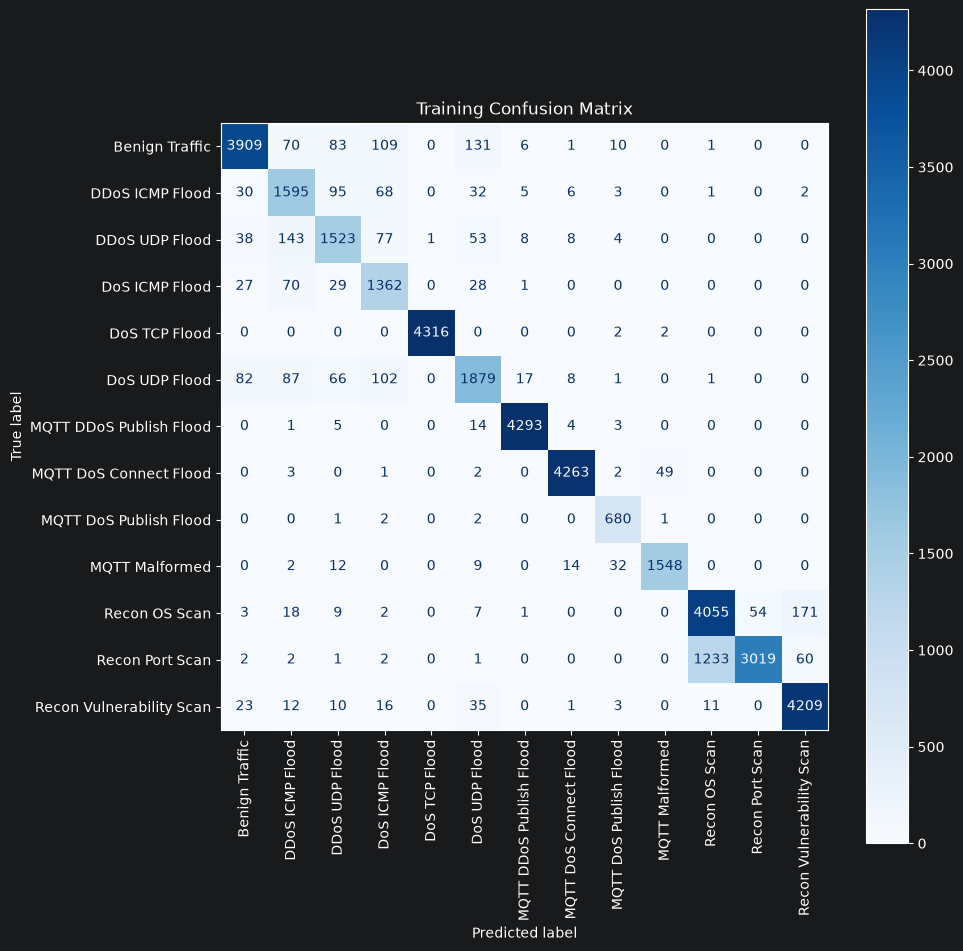

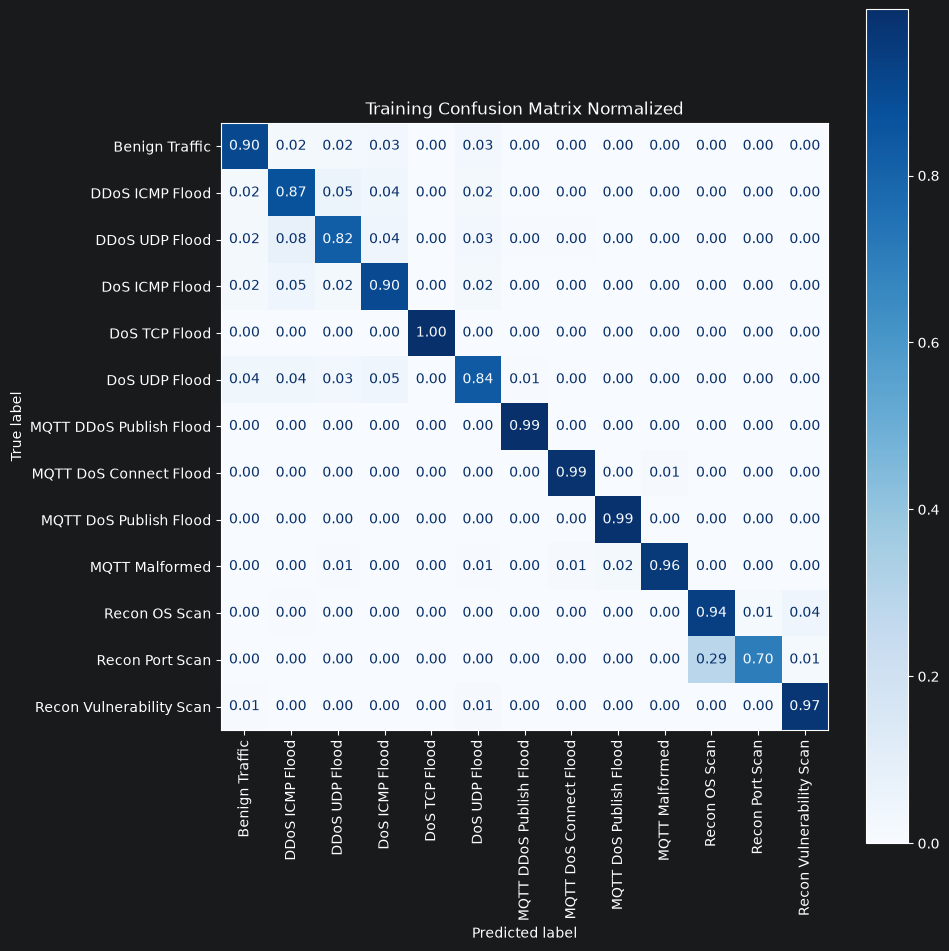

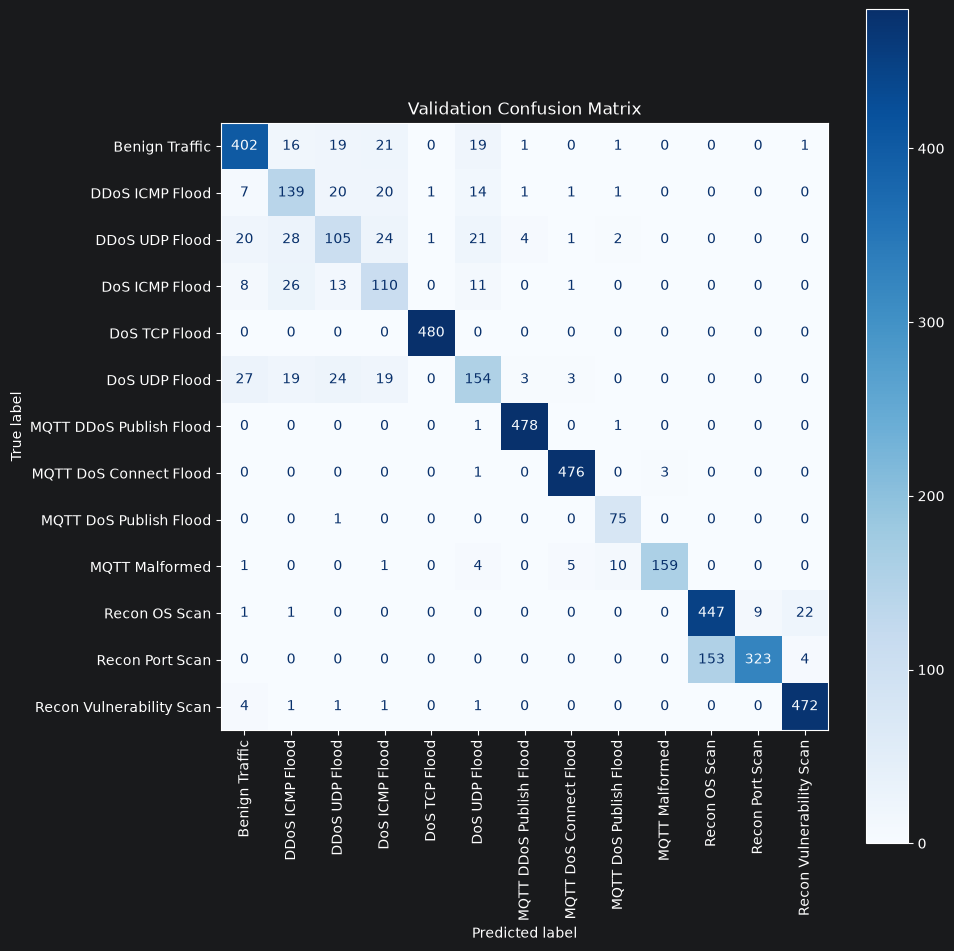

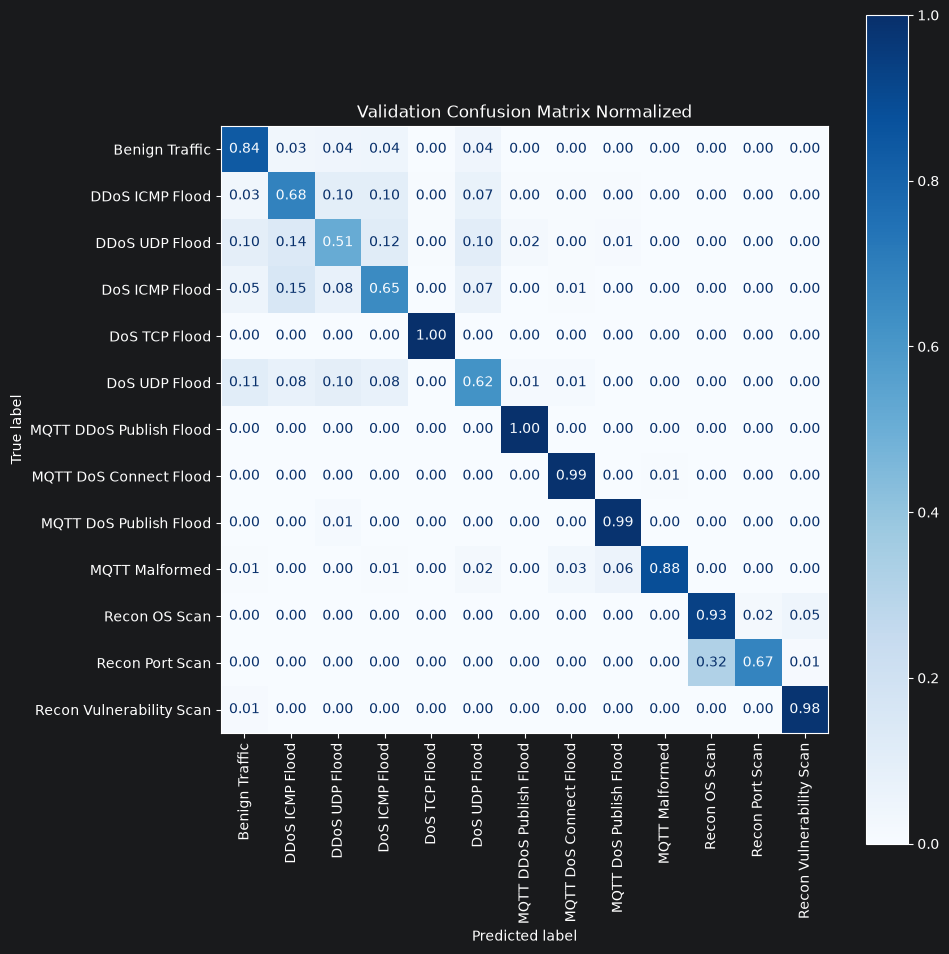

In [33]:
train_cm = plot_confusion_matrix(
    rf_model_best,
    features_train_holdout,
    targets_train_holdout,
    title="Training Confusion Matrix"
)

train_cm_norm = plot_confusion_matrix_norm(
    rf_model_best,
    features_train_holdout,
    targets_train_holdout,
    title="Training Confusion Matrix Normalized"
)

val_cm = plot_confusion_matrix(
    rf_model_best,
    features_val_holdout,
    targets_val_holdout,
    title="Validation Confusion Matrix"
)

val_cm_norm = plot_confusion_matrix_norm(
    rf_model_best,
    features_val_holdout,
    targets_val_holdout,
    title="Validation Confusion Matrix Normalized"
)